# Notebook 4: Folding cancer-gene mutants from CCLE with ESMFold (INSTRUCTOR VERSION, with solutions)

**LLMs in Bioinformatics workshop, folding block** | ~75 minutes | internet needed | GPU recommended

ESMFold predicts a 3D structure from **one amino-acid sequence**, using a protein language model (ESM-2) instead of an alignment of relatives. In the cancer cell lines of CCLE, some cancer genes carry **missense mutations** (one amino acid replaced). Notebook 2 gave you, for the same cell lines, the **protein level** and the **RNA level**. So you can ask a question about every mutation:

> *Does the predicted structure of the mutant look different, and does the cell line that carries it have less protein than its RNA would suggest?*

If a mutation makes the protein unstable, the cell may degrade it: **protein lower than RNA**. That is a real, measured signal, and it is what you will compare the structures against.

By the end you will be able to:

1. read mutations from the CCLE table and **check them against the UniProt sequence**;
2. fold a sequence (hosted service or local GPU) and **read the PDB file** yourself;
3. interpret **pLDDT** (per-residue confidence) and compare two structures with **RMSD**;
4. compute a simple **structure feature** (burial) and test it against **measured protein levels**, with an honest view of how little a few variants can show.

### Time plan (75 min)

| Time | Part | What happens |
| --- | --- | --- |
| 0:00-0:08 | **0. Setup** | install, settings, load the CCLE table |
| 0:08-0:20 | **1. Mutations and sequences** | read protein changes, fetch UniProt sequences, check the reference residues |
| 0:20-0:38 | **2. Fold and read confidence** | fold the TP53 core domain, parse the PDB, plot pLDDT |
| 0:38-0:55 | **3. Does folding see mutations?** | wild type vs three famous TP53 hotspots vs a scrambled control |
| 0:55-1:08 | **4. Structure vs measured protein** | burial, RMSD and pLDDT vs protein-minus-RNA in the carrying cell lines |
| 1:08-1:15 | **5. Open time** | challenges, troubleshooting |

Each part: **predict -> try (TODO) -> check cell -> debrief**. Write predictions before you run result cells.

> **Before you start:** switch to a GPU now (*Runtime > Change runtime type > T4 GPU*). The public folding service is often busy, and then the notebook folds on your GPU instead. The first GPU fold downloads an **8.4 GB model (5 to 10 minutes)**; every later fold takes seconds. Start Part 0 and the first fold early, and do not run other large models in the same session.

## Part 0. Setup (8 min)

Two ways to fold:

- **`FOLD_MODE = "api"`** (default): sends the sequence to the public **ESM Atlas** folding service. No GPU. Sequences should stay short (a domain, not a whole protein). If the service is down and your runtime has a GPU, the notebook switches to local folding by itself.
- **`FOLD_MODE = "local"`**: runs ESMFold from Hugging Face on a **GPU runtime** (about 8.4 GB download on the first fold; we use a small chunk size to fit a free T4). **A T4 GPU runtime is strongly recommended**: Part 4 folds about 10 structures.

**Data.** Upload `ccle_multiomics_panel.csv` (the output of Notebook 2, Part 4; your instructor can share a copy) to this Colab session (left sidebar, Files). It has one row per cell line and gene, with the columns `protein`, `rna_log2tpm`, `copy_number` and `mutation` (the protein change, for example `p.R175H`; blank if none).

In [1]:
!pip -q install transformers accelerate biopython requests 2>&1 | tail -1

In [2]:
import os, re, io, json, time, hashlib, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import requests
from scipy.stats import spearmanr
warnings.filterwarnings("ignore")


# Class data files: downloaded automatically from the course site (nothing to upload).
import os, requests
CLASS_FILES_URL = "https://raw.githubusercontent.com/AmirAliLoghmani80/CBH-Workshop/main/data/"
def get_class_file(name):
    if os.path.exists(name):
        return name
    if "YOUR-USER" in CLASS_FILES_URL:
        print(f"NOTE: {name} not found and no download address is set. Upload it (left sidebar, Files) or ask the instructor.")
        return None
    r = requests.get(CLASS_FILES_URL + name, timeout=120)
    if r.status_code != 200 or r.content[:15].lstrip().lower().startswith((b"<!doctype", b"<html")):
        print(f"NOTE: could not download {name} (HTTP {r.status_code}). Upload it (left sidebar, Files) or ask the instructor.")
        return None
    with open(name, "wb") as f:
        f.write(r.content)
    print(f"downloaded {name} ({len(r.content)/1e6:.1f} MB)")
    return name

CCLE_FILE = "ccle_multiomics_panel.csv"
get_class_file(CCLE_FILE)
FOLD_MODE = "api"            # "api" (no GPU) or "local" (GPU runtime)
# four cancer genes whose proteins are short enough to fold: UniProt id, and the fragment (first, last residue) we fold
GENES = {"TP53": ("P04637", (94, 312)),      # the DNA-binding core domain
         "KRAS": ("P01116", (1, 189)),
         "CDKN2A": ("P42771", (1, 156)),
         "PTEN": ("P60484", (1, 353))}       # phosphatase and C2 domains
os.makedirs("folds", exist_ok=True)

ccle = pd.read_csv(CCLE_FILE)
if "mutation" not in ccle.columns:
    raise ValueError(f"{CCLE_FILE} has no 'mutation' column. It needs the class file ccle_panel.csv in Notebook 2, Part 4.")
ccle["mutation"] = ccle["mutation"].fillna("").astype(str)
print(f"{ccle['cell_line'].nunique()} cell lines, {ccle['gene'].nunique()} genes; fold mode: {FOLD_MODE}")
print("rows with a mutation:", (ccle["mutation"] != "").sum())
print(ccle[ccle["mutation"] != ""][["cell_line", "gene", "mutation"]].head())

downloaded ccle_multiomics_panel.csv (0.4 MB)
371 cell lines, 19 genes; fold mode: api
rows with a mutation: 691
                                     cell_line  gene       mutation
94                          HEC50B_ENDOMETRIUM  AKT1         p.E40K
141  JURKAT_HAEMATOPOIETIC_AND_LYMPHOID_TISSUE  AKT1        p.R200H
156                               KP2_PANCREAS  AKT1        p.G478S
159                       KU1919_URINARY_TRACT  AKT1  p.E17K;p.E49K
164                          KYSE30_OESOPHAGUS  AKT1         p.P51L


## Part 1. Mutations and sequences (12 min)

The `mutation` column holds a protein change written like `p.R175H`: reference amino acid (`R`, arginine), **position 175**, new amino acid (`H`, histidine). Other changes look different: `p.R213*` is a stop (nonsense), `p.E285fs` is a frameshift. Only the **missense** ones (one letter, a number, one letter) are what a structure predictor can fold. A cell line can carry several changes in one gene, written with `;` between them.

**TODO 1.** Write `parse_protein_change(text)`. It receives the text of one cell, for example `"p.R175H"` or `"p.R175H;p.G245S"`, and returns a list of `(ref, pos, alt)` tuples for the **missense changes only**: `("R", 175, "H")`. Nonsense, frameshift and anything else are ignored. An empty text returns `[]`.

In [3]:
MISSENSE = re.compile(r"^p\.([A-Z])(\d+)([A-Z])$")      # p.R175H: one letter, digits, one letter

def parse_protein_change(text):
    out = []
    for part in re.split(r"[;,]\s*", text):
        part = part.strip()
        # TODO 1: match the pattern, and append (ref, int(position), alt) when it matches
        m = MISSENSE.match(part)
        if m:
            out.append((m.group(1), int(m.group(2)), m.group(3)))
    return out

In [4]:
# CHECK 1
try:
    assert parse_protein_change("p.R175H") == [("R", 175, "H")], f"got {parse_protein_change('p.R175H')}"
    assert parse_protein_change("p.R175H;p.G245S") == [("R", 175, "H"), ("G", 245, "S")], "two changes in one cell"
    assert parse_protein_change("p.R213*") == [] and parse_protein_change("p.E285fs") == [], "nonsense and frameshift must be ignored"
    assert parse_protein_change("") == [], "empty text gives an empty list"
    print("OK. parse_protein_change works")
except TypeError as e:
    raise AssertionError("TODO 1 not finished: use MISSENSE.match(part) and append a tuple") from e

OK. parse_protein_change works


Now fetch the four proteins from **UniProt** and test an important assumption: that the position in the table refers to the same protein sequence as UniProt. If the **reference amino acid** in the table does not match the sequence at that position, the numbering (or the isoform) differs, and folding the "mutant" would silently fold the wrong thing.

In [5]:
def fetch_uniprot(acc):
    r = requests.get(f"https://rest.uniprot.org/uniprotkb/{acc}.json", timeout=60)
    r.raise_for_status()
    return r.json()["sequence"]["value"]

SEQS = {g: fetch_uniprot(acc) for g, (acc, _) in GENES.items()}

rows = []
for g in GENES:
    sub = ccle[(ccle["gene"] == g) & (ccle["mutation"] != "")]
    for line, text in zip(sub["cell_line"], sub["mutation"]):
        entries = [x for x in re.split(r"[;,]\s*", text) if x.strip()]
        for ref, pos, alt in parse_protein_change(text):
            rows.append({"gene": g, "cell_line": line, "ref": ref, "pos": pos, "alt": alt, "n_changes": len(entries),
                         "ref_matches": pos <= len(SEQS[g]) and SEQS[g][pos - 1] == ref})
muts = pd.DataFrame(rows)
print(muts.groupby("gene").agg(lines=("cell_line", "nunique"), distinct_positions=("pos", "nunique"),
                              ref_matches=("ref_matches", "mean")).round(2))
print("protein lengths:", {g: len(s) for g, s in SEQS.items()})
assert muts["ref_matches"].mean() > 0.9, "Most reference residues do not match UniProt: the table uses another transcript or isoform. Print a few rows and compare with the UniProt page."
muts = muts[muts["ref_matches"]].drop(columns="ref_matches").reset_index(drop=True)
print(f"kept {len(muts)} missense carriers whose reference residue matches UniProt")

        lines  distinct_positions  ref_matches
gene                                          
CDKN2A     18                  13         0.94
KRAS       71                   8         0.99
PTEN       12                  13         1.00
TP53      173                  77         1.00
protein lengths: {'TP53': 393, 'KRAS': 189, 'CDKN2A': 156, 'PTEN': 403}
kept 292 missense carriers whose reference residue matches UniProt


**Why this matters for vibe coding:** an AI that writes this parser will usually forget the reference-residue check. It is the same lesson as Notebook 3: **check the reference**, because wrong coordinates do not raise an error, they just give a plausible answer about the wrong thing.

## Part 2. Fold and read the confidence (18 min)

We start with the **TP53 core domain** (residues 94-312, the DNA-binding part where most cancer mutations sit). ESMFold writes its answer as a **PDB file** (plain text). Each atom is one line; fixed columns hold the coordinates. ESMFold stores its per-residue confidence **pLDDT** in the "B-factor" column.

| pLDDT | Meaning |
| --- | --- |
| > 90 | very high confidence |
| 70-90 | confident |
| 50-70 | low |
| < 50 | probably disordered, or the model does not know |

In [6]:
def fragment(gene):
    lo, hi = GENES[gene][1]
    return lo, hi, SEQS[gene][lo - 1:hi]

tp_lo, tp_hi, TP53_SEQ = fragment("TP53")
print(f"TP53 core: residues {tp_lo}-{tp_hi} ({len(TP53_SEQ)} aa)")
print(TP53_SEQ)

TP53 core: residues 94-312 (219 aa)
SSSVPSQKTYQGSYGFRLGFLHSGTAKSVTCTYSPALNKMFCQLAKTCPVQLWVDSTPPPGTRVRAMAIYKQSQHMTEVVRRCPHHERCSDSDGLAPPQHLIRVEGNLRVEYLDDRNTFRHSVVVPYEPPEVGSDCTTIHYNYMCNSSCMGGMNRRPILTIITLEDSSGNLLGRNSFEVRVCACPGRDRRTEEENLRKKGEPHHELPPGSTKRALPNNT


In [7]:
PREFOLDED_STRUCTURES = False      # True: also look for pre-folded structures in the course repository (folds/)
ESM_ATLAS_URL = "https://api.esmatlas.com/foldSequence/v1/pdb/"

def fold_api(seq):
    for attempt in range(3):
        try:
            r = requests.post(ESM_ATLAS_URL, data=seq, headers={"Content-Type": "text/plain"}, timeout=120)
        except requests.RequestException as e:
            r = type("R", (), {"status_code": type(e).__name__, "text": str(e)})()
        if r.status_code == 200 and r.text.startswith(("HEADER", "ATOM", "PARENT", "REMARK", "MODEL")):
            return r.text
        time.sleep(3 * (attempt + 1))
    raise RuntimeError(f"folding service answered {r.status_code}: {r.text[:200]}. "
                       "Try again, shorten the sequence, or switch FOLD_MODE to 'local' on a GPU runtime.")

_local = {}
def fold_local(seq):
    import torch
    from transformers import AutoTokenizer, EsmForProteinFolding
    from transformers.models.esm.openfold_utils.protein import to_pdb, Protein as OFProtein
    from transformers.models.esm.openfold_utils.feats import atom14_to_atom37
    if "model" not in _local:
        _local["tok"] = AutoTokenizer.from_pretrained("facebook/esmfold_v1")
        import gc
        try:
            # load the weights straight onto the GPU, so the 8 GB never sits in the (small) CPU memory of a free Colab
            m = EsmForProteinFolding.from_pretrained("facebook/esmfold_v1", low_cpu_mem_usage=True, use_safetensors=True,
                                                     device_map="cuda").eval()
        except Exception as e:
            print("Direct GPU loading failed (", type(e).__name__, "); trying the standard way.")
            gc.collect(); torch.cuda.empty_cache()
            m = EsmForProteinFolding.from_pretrained("facebook/esmfold_v1", low_cpu_mem_usage=True, use_safetensors=True).cuda().eval()
        gc.collect()
        m.esm = m.esm.half()
        m.trunk.set_chunk_size(64)
        _local["model"] = m
    tok, model = _local["tok"], _local["model"]
    ids = tok([seq], return_tensors="pt", add_special_tokens=False)["input_ids"].cuda()
    with torch.no_grad():
        out = model(ids)
    pos = atom14_to_atom37(out["positions"][-1], out)
    out = {k: v.to("cpu").numpy() for k, v in out.items()}
    pos = pos.cpu().numpy()
    pred = OFProtein(aatype=out["aatype"][0], atom_positions=pos[0], atom_mask=out["atom37_atom_exists"][0],
                     residue_index=out["residue_index"][0] + 1, b_factors=out["plddt"][0])
    return to_pdb(pred)

def fold(seq):
    """Fold a sequence; results are cached on disk by sequence hash.
    In "api" mode, if the public service is down and this runtime has a GPU, fall back to local ESMFold."""
    h = hashlib.md5(seq.encode()).hexdigest()[:12]
    for mode in (FOLD_MODE, "local"):
        if os.path.exists(f"folds/{mode}_{h}.pdb"):
            return open(f"folds/{mode}_{h}.pdb").read()
    if PREFOLDED_STRUCTURES:          # pre-folded structures shared by the instructor (nothing to fold, no GPU)
        for mode in ("api", "local"):
            try:
                r = requests.get(f"{CLASS_FILES_URL}folds/{mode}_{h}.pdb", timeout=60)
                if r.status_code == 200 and r.text.startswith(("HEADER", "ATOM", "PARENT", "REMARK", "MODEL")):
                    open(f"folds/{mode}_{h}.pdb", "w").write(r.text)
                    return r.text
            except requests.RequestException:
                pass
    used = FOLD_MODE
    if FOLD_MODE == "api":
        try:
            txt = fold_api(seq)
        except RuntimeError as e:
            import torch
            if not torch.cuda.is_available():
                raise RuntimeError(str(e) + "\n\nThe public folding service is not answering and this runtime has no GPU. "
                                   "Fix: Runtime > Change runtime type > T4 GPU, run the setup cell again, set FOLD_MODE = 'local' and re-run this cell.") from None
            print("Public folding service failed; using the GPU in this runtime instead (first run downloads about 8.4 GB and takes 5-10 min; later folds take seconds).")
            txt, used = fold_local(seq), "local"
    else:
        txt = fold_local(seq)
    open(f"folds/{used}_{h}.pdb", "w").write(txt)
    return txt

t0 = time.time()
tp_pdb = fold(TP53_SEQ)
print(f"folded {len(TP53_SEQ)} residues in {time.time() - t0:.0f} s; PDB has {tp_pdb.count(chr(10))} lines")
print("\n".join(tp_pdb.split("\n")[:4]))

folded 219 residues in 1 s; PDB has 1736 lines
HEADER                                            18-OCT-22                     
TITLE     ESMFOLD V1 PREDICTION FOR INPUT
REMARK   1                                                                      
REMARK   1 REFERENCE 1                                                          


**TODO 2.** Read the PDB yourself. Atom lines start with `ATOM`; the **atom name** is in columns 13-16 (`line[12:16]`), the **x, y, z** coordinates are in columns 31-54 (`line[30:38]`, `line[38:46]`, `line[46:54]`), and the **B-factor (= pLDDT)** is in columns 61-66 (`line[60:66]`). Keep only the **C-alpha** (`CA`) atoms: one per residue.

In [8]:
def parse_pdb(text):
    """Return (ca_xyz [n,3], plddt [n]) for one chain. pLDDT is scaled to 0-100."""
    xyz, plddt = [], []
    for line in text.split("\n"):
        if line.startswith("ATOM") and line[12:16].strip() == "CA":
            # TODO 2: read x, y, z from the fixed columns and the B-factor from line[60:66]
            x = float(line[30:38])
            y = float(line[38:46])
            z = float(line[46:54])
            b = float(line[60:66])
            xyz.append([x, y, z]); plddt.append(b)
    xyz, plddt = np.array(xyz), np.array(plddt)
    if len(plddt) and plddt.max() <= 1.0:      # some tools write 0-1, others 0-100
        plddt = plddt * 100
    return xyz, plddt

In [9]:
# CHECK 2: a tiny hand-written PDB with known numbers
_toy = ("ATOM      1  N   ALA A   1      10.000  20.000  30.000  1.00 91.50           N\n"
        "ATOM      2  CA  ALA A   1      11.500  21.250  31.750  1.00 91.50           C\n"
        "ATOM      3  CA  GLY A   2      13.000  22.000  33.000  1.00 45.00           C\n")
try:
    _xyz, _pl = parse_pdb(_toy)
    assert _xyz.shape == (2, 3), f"expected 2 C-alpha atoms (CA lines only), got shape {_xyz.shape}"
    assert np.allclose(_xyz[0], [11.5, 21.25, 31.75]), f"coordinates look wrong: {_xyz[0]}"
    assert np.allclose(_pl, [91.5, 45.0]), f"pLDDT looks wrong: {_pl}"
    print("OK. parse_pdb works on the toy file")
except (TypeError, ValueError) as e:
    raise AssertionError("TODO 2 not finished: replace each ... with float(line[a:b]) using the column ranges above") from e

OK. parse_pdb works on the toy file


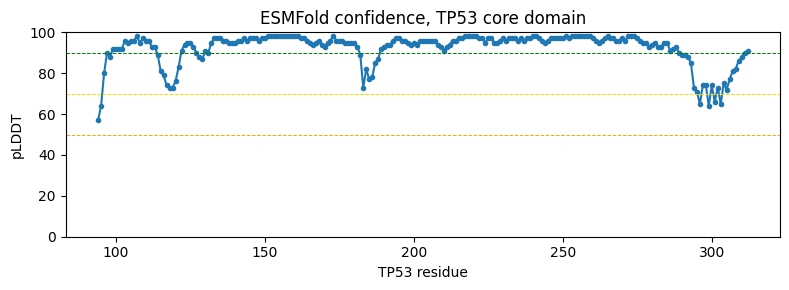

mean pLDDT 92.3; residues below 70: 6 of 219


In [10]:
tp_xyz, tp_plddt = parse_pdb(tp_pdb)
assert len(tp_xyz) == len(TP53_SEQ), f"{len(tp_xyz)} residues in the PDB vs {len(TP53_SEQ)} in the sequence"
res_no = np.arange(tp_lo, tp_hi + 1)

fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(res_no, tp_plddt, marker="o", ms=3)
for y, c in [(90, "green"), (70, "gold"), (50, "orange")]:
    ax.axhline(y, ls="--", lw=0.7, color=c)
ax.set_xlabel("TP53 residue"); ax.set_ylabel("pLDDT"); ax.set_ylim(0, 100)
ax.set_title("ESMFold confidence, TP53 core domain"); plt.tight_layout(); plt.show()
print(f"mean pLDDT {tp_plddt.mean():.1f}; residues below 70: {(tp_plddt < 70).sum()} of {len(tp_plddt)}")

**Debrief.**

- Where is the model least confident, and does that match the edges of the fragment you cut?
- pLDDT is the model's **opinion of itself**. It is not a measured error. What kind of experiment would test it? (The PDB database holds experimental structures of the p53 core domain.)
- This is a **foundation-model output without a ground truth in your hands**. Name one way you could check it today.

## Part 3. Does folding see mutations? (17 min)

TP53 is mutated in about half of all human cancers, and three **hotspots** account for a large share of the missense mutations: **R175H**, **R248Q** and **R273H**. R248 and R273 touch the DNA; R175 helps hold the fold together. We fold the wild type and each mutant and compare.

**Prediction (write it down):** ESMFold folds the mutant. Compared with the wild type, will the **overall shape** change a lot, a little, or not at all? And what about the **pLDDT** near the mutated site?

**My prediction:** shape: ________  pLDDT near the site: ________

**TODO 3.** Write `mutate(seq, pos, new_aa)` where `pos` is the **1-based position in `seq`**. This is the classic place for off-by-one errors, and for mixing up *whole-protein* numbering with *fragment* numbering (the fragment starts at residue 94, not 1).

In [11]:
def mutate(seq, pos, new_aa):
    """Return seq with the residue at 1-based position `pos` replaced by new_aa."""
    # TODO 3: remember Python counts from 0
    return seq[:pos - 1] + new_aa + seq[pos:]

In [12]:
# CHECK 3
try:
    assert mutate("ACDE", 2, "W") == "AWDE", f"mutate('ACDE', 2, 'W') gave {mutate('ACDE', 2, 'W')!r}, expected 'AWDE'"
    assert mutate("ACDE", 1, "W") == "WCDE" and mutate("ACDE", 4, "W") == "ACDW", "first/last position are wrong"
    print("OK. mutate works")
except TypeError as e:
    raise AssertionError("TODO 3 not finished: build the new string from seq[:pos-1], new_aa and seq[pos:]") from e

OK. mutate works


In [13]:
def kabsch_rmsd(P, Q):
    """RMSD between two coordinate sets after the best rotation + translation."""
    P = P - P.mean(0); Q = Q - Q.mean(0)
    U, S, Vt = np.linalg.svd(P.T @ Q)
    d = np.sign(np.linalg.det(U @ Vt))
    D = np.diag([1, 1, d])
    R = U @ D @ Vt
    return float(np.sqrt(((P @ R - Q) ** 2).sum(1).mean()))

def compare_variant(gene, ref, pos, alt):
    """Fold the wild-type fragment and the fragment with the variant; compare. Returns a dict, or None if outside the fragment."""
    lo, hi, wt = fragment(gene)
    if not lo <= pos <= hi:
        return None
    assert SEQS[gene][pos - 1] == ref, f"{gene} residue {pos} is {SEQS[gene][pos - 1]}, not {ref}: check the numbering"
    mut = mutate(wt, pos - lo + 1, alt)             # fragment numbering = whole-protein numbering - lo + 1
    xyz_w, pl_w = parse_pdb(fold(wt)); xyz_m, pl_m = parse_pdb(fold(mut))
    i = pos - lo
    site = slice(max(0, i - 2), i + 3)
    return {"variant": f"{gene} {ref}{pos}{alt}", "RMSD (A)": kabsch_rmsd(xyz_w, xyz_m),
            "mean pLDDT wt": pl_w.mean(), "mean pLDDT mut": pl_m.mean(),
            "site pLDDT wt": pl_w[site].mean(), "site pLDDT mut": pl_m[site].mean()}

rows = []
for ref, pos, alt in [("R", 175, "H"), ("R", 248, "Q"), ("R", 273, "H")]:
    rows.append(compare_variant("TP53", ref, pos, alt))

# Negative control: the same residues in scrambled order (same composition, no biology)
rng = np.random.default_rng(0)
scr = "".join(rng.permutation(list(TP53_SEQ)))
_, pl_s = parse_pdb(fold(scr))
res3 = pd.DataFrame(rows).set_index("variant")
print(res3.round(2).to_string())
print(f"\nscrambled TP53 control: mean pLDDT {pl_s.mean():.1f} (wild-type core: {tp_plddt.mean():.1f})")

Public folding service failed; using the GPU in this runtime instead (first run downloads about 8.4 GB and takes 5-10 min; later folds take seconds).


config.json:   0%|          | 0.00/2.10k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/40.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/72.0 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/121 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 8.44GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/4498 [00:00<?, ?it/s]

[transformers] EsmForProteinFolding LOAD REPORT from: facebook/esmfold_v1
Key                                | Status  | 
-----------------------------------+---------+-
esm.contact_head.regression.bias   | MISSING | 
esm.contact_head.regression.weight | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


            RMSD (A)  mean pLDDT wt  mean pLDDT mut  site pLDDT wt  site pLDDT mut
variant                                                                           
TP53 R175H      0.37          92.27           91.68           96.2            92.2
TP53 R248Q      0.12          92.27           92.20           97.0            97.0
TP53 R273H      0.18          92.27           92.12           97.4            97.4

scrambled TP53 control: mean pLDDT 32.9 (wild-type core: 92.3)


**Debrief.**

- Was your prediction right? A hotspot mutation can wreck a protein's function while the **predicted backbone barely moves**. A fold predictor trained to produce the likely structure for a sequence is not the same as a predictor of **stability or function**.
- **What the model cannot see.** The hotspot structures differ from wild type by well under 1 A and keep their confidence, yet these proteins are known to accumulate in cancer cells. State in one sentence what ESMFold was trained to do and what it was not trained to do.
- What is the scrambled control for? What would you conclude if its pLDDT were as high as the wild type's?
- A model can be impressive at one task (folding natural sequences) and weak at the task you actually need (telling a harmful variant from a harmless one): Notebook 5. Which score would you want before using ESMFold for variant interpretation?

## Part 4. Structure vs measured protein (13 min)

Now the experiment. For each **missense variant carried by cell lines in the table**, we have the **measured protein and RNA** of the cell lines that carry it. We turn that into one number per variant:

- For each gene, take the cell lines **without** any mutation in that gene as the reference, and express protein and RNA of a carrying line as **z-scores** (how many standard deviations above or below the reference).
- **`protein minus RNA`** = protein z-score minus RNA z-score. Negative: the cell has **less protein than its RNA predicts**, as if the mutant protein is degraded. Zero: protein follows RNA.

And from the structure, three numbers per variant: the **RMSD** between wild type and mutant, the **drop in pLDDT** around the site, and the **burial** of the site (how many other residues are within 10 A). A buried residue is usually less tolerant of change.

**TODO 4.** Compute the burial for every residue from a coordinate array `xyz` of shape `[n, 3]`.

In [14]:
def burial(xyz, radius=10.0):
    """For each residue: number of OTHER residues whose C-alpha is within `radius` angstrom."""
    d = np.linalg.norm(xyz[:, None, :] - xyz[None, :, :], axis=-1)      # [n, n] distance matrix
    # TODO 4: count entries below the radius in each row, and do not count the residue itself
    return (d < radius).sum(axis=1) - 1

In [15]:
# CHECK 4: five points on a line, 4 A apart: the middle one has 4 neighbours within 10 A, the ends have 2
try:
    _line = np.array([[4.0 * i, 0, 0] for i in range(5)])
    _b = np.asarray(burial(_line))
    assert list(_b) == [2, 3, 4, 3, 2], f"expected [2, 3, 4, 3, 2], got {list(_b)}"
    print("OK. burial works")
except TypeError as e:
    raise AssertionError("TODO 4 not finished: use (d < radius).sum(axis=1) - 1") from e

OK. burial works


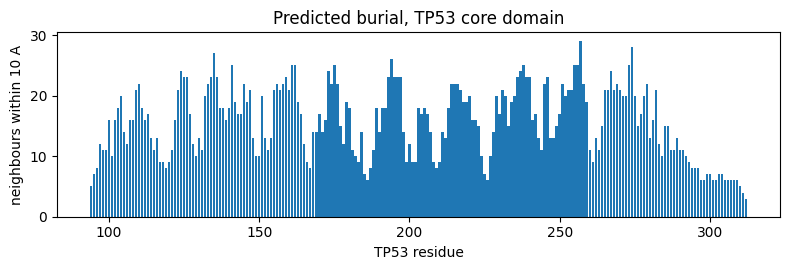

In [16]:
tp_burial = burial(tp_xyz)
fig, ax = plt.subplots(figsize=(8, 2.8))
ax.bar(res_no, tp_burial); ax.set_xlabel("TP53 residue"); ax.set_ylabel("neighbours within 10 A")
ax.set_title("Predicted burial, TP53 core domain"); plt.tight_layout(); plt.show()

### The measured signal, and the variants to fold

Pick the most frequent variants per gene (those with the most carrying cell lines, and at least `MIN_LINES` = 3 of them: one cell line is an anecdote, not a measurement), inside the folded fragments, carried **alone** (a line with a single change in that gene, so that the signal is not mixed). `PER_GENE` sets how many per gene; each variant costs one fold, so keep it small on a free GPU.

In [17]:
PER_GENE = 4
MIN_LINES = 3         # a variant must be carried alone by at least this many cell lines with protein and RNA data
MIN_REF = 10          # reference lines (no mutation in the gene) needed for a z-score

def zscores(gene):
    sub = ccle[ccle["gene"] == gene].copy()
    ref = sub[(sub["mutation"] == "") & sub["protein"].notna() & sub["rna_log2tpm"].notna()]
    if len(ref) < MIN_REF:
        return None
    mu = ref[["protein", "rna_log2tpm"]].mean(); sd = ref[["protein", "rna_log2tpm"]].std().replace(0, np.nan)
    return mu, sd

def observed_signal(gene, ref_aa, pos, alt):
    z = zscores(gene)
    if z is None:
        return np.nan, 0
    mu, sd = z
    carriers = muts[(muts.gene == gene) & (muts.ref == ref_aa) & (muts.pos == pos) & (muts.alt == alt) & (muts.n_changes == 1)]["cell_line"]
    sub = ccle[(ccle.gene == gene) & ccle.cell_line.isin(carriers) & ccle.protein.notna() & ccle.rna_log2tpm.notna()]
    if sub.empty:
        return np.nan, 0
    zp = (sub["protein"] - mu["protein"]) / sd["protein"]
    zr = (sub["rna_log2tpm"] - mu["rna_log2tpm"]) / sd["rna_log2tpm"]
    return float((zp - zr).mean()), len(sub)

cand = []
for g in GENES:
    lo, hi, _ = fragment(g)
    sub = muts[(muts.gene == g) & (muts.n_changes == 1) & muts.pos.between(lo, hi)]
    top = sub.groupby(["ref", "pos", "alt"]).size().sort_values(ascending=False).head(PER_GENE)
    for (ref_aa, pos, alt), n in top.items():
        sig, n_ok = observed_signal(g, ref_aa, pos, alt)
        if n_ok >= MIN_LINES:
            cand.append({"gene": g, "ref": ref_aa, "pos": pos, "alt": alt, "lines": n_ok, "protein_minus_rna": sig})
cand = pd.DataFrame(cand)
print(f"{len(cand)} variants to fold")
cand

9 variants to fold


,gene,ref,pos,alt,lines,protein_minus_rna
0,TP53,R,248,Q,13,3.475284
1,TP53,R,273,H,9,2.300185
2,TP53,R,175,H,9,1.927059
3,TP53,R,248,W,9,2.761753
4,KRAS,G,12,D,17,0.812158
5,KRAS,G,12,C,14,0.358109
6,KRAS,G,12,V,13,0.504165
7,KRAS,G,13,D,7,0.264080
8,CDKN2A,H,83,Y,3,-0.793261


In [18]:
t0 = time.time()
feat = []
for _, r in cand.iterrows():
    res = compare_variant(r.gene, r.ref, int(r.pos), r.alt)
    lo, hi, wt = fragment(r.gene)
    xyz_w, _ = parse_pdb(fold(wt))
    res.update({"gene": r.gene, "lines": r.lines, "protein_minus_rna": r.protein_minus_rna,
                "burial": float(burial(xyz_w)[int(r.pos) - lo]),
                "dpLDDT_site": res["site pLDDT wt"] - res["site pLDDT mut"]})
    feat.append(res)
feat = pd.DataFrame(feat)
print(f"folded {len(feat)} variants in {time.time() - t0:.0f} s")
feat[["variant", "lines", "protein_minus_rna", "RMSD (A)", "dpLDDT_site", "burial"]].round(2)

folded 9 variants in 11 s


,variant,lines,protein_minus_rna,RMSD (A),dpLDDT_site,burial
0,TP53 R248Q,13,3.48,0.12,0.0,13.0
1,TP53 R273H,9,2.30,0.18,0.0,25.0
2,TP53 R175H,9,1.93,0.37,4.0,25.0
3,TP53 R248W,9,2.76,0.09,-0.2,13.0
4,KRAS G12D,17,0.81,0.17,-0.6,19.0
5,KRAS G12C,14,0.36,0.18,-0.2,19.0
6,KRAS G12V,13,0.50,0.18,-0.4,19.0
7,KRAS G13D,7,0.26,0.42,-0.4,16.0
8,CDKN2A H83Y,3,-0.79,1.37,1.0,24.0


n = 9 variants
Spearman: burial       vs protein-minus-RNA = -0.27  (p = 0.48)
Spearman: RMSD (A)     vs protein-minus-RNA = -0.73  (p = 0.02)
Spearman: dpLDDT_site  vs protein-minus-RNA = +0.18  (p = 0.65)


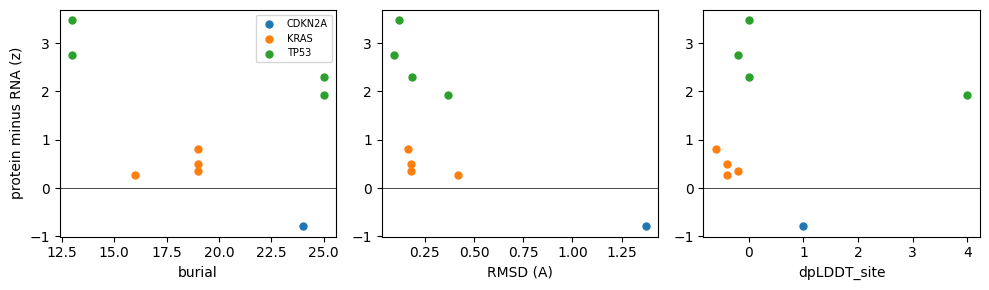


The same variants, summarised per gene (each point above belongs to one gene):


,variants,signal,RMSD,burial,dpLDDT
gene,,,,,
CDKN2A,1,-0.79,1.37,24.00,1.00
KRAS,4,0.48,0.24,18.25,-0.40
TP53,4,2.62,0.19,19.00,0.95


Within one gene there are too few variants for a correlation. Do the genes differ in structure change AND in signal at the same time?


In [19]:
try:
    from IPython.display import display
except ImportError:
    display = print
if len(feat) >= 6:
    print(f"n = {len(feat)} variants")
    for col in ["burial", "RMSD (A)", "dpLDDT_site"]:
        r_ = spearmanr(feat[col], feat["protein_minus_rna"])
        print(f"Spearman: {col:12s} vs protein-minus-RNA = {r_.statistic:+.2f}  (p = {r_.pvalue:.2f})")
    fig, ax = plt.subplots(1, 3, figsize=(10, 3))
    for a, col in zip(ax, ["burial", "RMSD (A)", "dpLDDT_site"]):
        for g, d in feat.groupby("gene"):
            a.scatter(d[col], d["protein_minus_rna"], label=g, s=25)
        a.set_xlabel(col); a.axhline(0, color="k", lw=0.5)
    ax[0].set_ylabel("protein minus RNA (z)"); ax[0].legend(fontsize=7)
    plt.tight_layout(); plt.show()
    print("\nThe same variants, summarised per gene (each point above belongs to one gene):")
    display(feat.groupby("gene").agg(variants=("variant", "count"), signal=("protein_minus_rna", "mean"), RMSD=("RMSD (A)", "mean"),
                                     burial=("burial", "mean"), dpLDDT=("dpLDDT_site", "mean")).round(2))
    print("Within one gene there are too few variants for a correlation. Do the genes differ in structure change AND in signal at the same time?")
else:
    print("Too few variants have data: check that the table has protein and RNA for the mutated lines.")

**Debrief.**

- Which sign did you expect for burial vs `protein minus RNA`? Does the data agree? With about 10 variants, how big must a correlation be before you would believe it? (Hint: look at the p-value, and at what one outlier does.)
- Look at the per-gene table. A correlation across all variants can come from differences **between genes** (one gene with a large RMSD and a low signal, another with a small RMSD and a high signal) and say nothing about structure inside a gene. Which genes drive it?
- Look at the genes separately. Is the picture the same for TP53, KRAS, CDKN2A and PTEN? **Mutant p53 protein is known to accumulate** in cells (the cell does not degrade it as it degrades normal p53), so for TP53 a *higher* protein-minus-RNA is not a surprise. A single rule across genes may be wrong.
- Burial, RMSD and pLDDT are **features made from a foundation model's output**. What would you compare them against to see whether they add anything? (Notebook 5: a simple baseline, and the right split.)
- A variant at a buried position does not have to lower the protein level; and a lower protein level can have causes that no structure shows (for example a change that affects how fast the mRNA is translated). What else does the protein-minus-RNA number contain that the structure does not?

## Part 5. Open time (7 min and beyond)

Pick **one** challenge.

**Challenge A: both folders.** Fold the TP53 core with the other `FOLD_MODE`. Do the two structures agree (RMSD)? Is pLDDT the same?

**Challenge B: more variants.** Raise `PER_GENE` to 8 (more folding time). Does the correlation get clearer or vanish?

**Challenge C: the experimental answer.** Download an experimental p53 core-domain structure from the PDB (find an entry on the RCSB website), compute the RMSD of the C-alpha atoms against your prediction. Remember to match **residue numbers**, not just counts.

**Challenge D: one gene only.** Restrict Part 4 to TP53 (raise `PER_GENE` for TP53 only). Is the sign of the relation the same as across all genes?

**Challenge E: what did the carrier lines have in common?** Count the lineages of the cell lines that carry each variant. Could the protein-minus-RNA signal reflect the tissue rather than the mutation?

## Troubleshooting

| Symptom | Likely cause | Fix |
| --- | --- | --- |
| `FileNotFoundError: ccle_multiomics_panel.csv` | file not uploaded | Upload it (left sidebar, Files) or ask the instructor |
| `no 'mutation' column` | the file was built without the class file | Use the version from Notebook 2 that includes `ccle_panel.csv` |
| `Most reference residues do not match UniProt` | the table uses another transcript | Print a few rows of `muts` and compare with the UniProt page; ask the instructor |
| Out of memory (RAM or GPU) while loading ESMFold | the model is 8.4 GB; a free Colab has about 12 GB of CPU memory and 15 GB of GPU memory | Runtime > Restart session, run only Part 0 and the folding cell (no other model loaded first); set `FOLD_MODE = "local"` before the first fold; still failing: use pre-folded structures from your instructor |
| `RuntimeError: folding service answered 504` | the public ESM Atlas service is overloaded or down (not your code) | On a GPU runtime the notebook switches to local ESMFold by itself. Otherwise: Runtime > Change runtime type > T4 GPU, set `FOLD_MODE = "local"`, re-run |
| `CUDA out of memory` (local) | GPU too small | Restart the runtime; keep the chunk size at 64 or smaller |
| Part 4 takes very long | about 10 folds | Lower `PER_GENE` to 2 |
| `... not finished` messages | a TODO still has `...` | Fill it in, rerun the TODO cell, then the check |
| Variable not defined | skipped a cell | Run all cells above (Runtime > Run before) |

## INSTRUCTOR NOTES

**Timing.** Parts 0-4 take about 68 minutes with a T4 GPU; Part 4 folds about 20 structures (each about 10-60 s once the model is loaded; the first fold downloads 8.4 GB, 5-10 min). Part 5 absorbs overruns. If behind, lower `PER_GENE` to 2.

**NOT verified (no network in the build environment).** Everything ran only against stand-ins:
- the CCLE table: the `mutation` column is built from DepMap's `ProteinChange` (format `p.R175H`). Check the real strings: nonsense look like `p.R213*`, frameshifts `p.E285fs`; if the release writes three-letter codes or another format, `parse_protein_change` returns nothing and Part 1 stops with a clear message;
- that DepMap's protein positions refer to the same isoform as UniProt's canonical sequence for TP53, KRAS, CDKN2A and PTEN. The notebook checks the reference residue and stops if more than 10% of the rows disagree. CDKN2A is the likeliest to differ (several isoforms);
- the UniProt accessions (TP53 P04637, KRAS P01116, CDKN2A P42771, PTEN P60484) and the fragment limits (TP53 94-312, PTEN 1-353);
- the **ESM Atlas** endpoint and local ESMFold on a T4 (this part of the code ran on real Colab runs in an earlier version of this notebook, with BRCA1 domains);
- what the data say. I do not know whether burial, RMSD or pLDDT correlates with protein-minus-RNA, and with about 16 variants it probably will not be clear. The debrief is written so that "no clear relation" is a useful result. Do not tell participants what to expect.

**Biology to be ready for.** Many TP53 missense mutants are *stabilised*: mutant p53 protein accumulates, so protein-minus-RNA can be positive. PTEN and CDKN2A missense mutants are more often unstable (lower protein). KRAS hotspot mutants (G12, G13, Q61) do not usually change the protein level. That is why Part 4 asks participants to look at genes separately.

**Before the workshop.**
1. Run the notebook once on a T4; check the variants chosen in Part 4 and the reference-residue message in Part 1.
2. Zip the `folds/` directory and share it as a cache for participants without a GPU (the cache key is the sequence hash, so it works with any `PER_GENE`).
3. Share `ccle_multiomics_panel.csv` (output of Notebook 2, built with the class file `ccle_panel.csv`).

**What the first real run showed (11 Nov, 26Q3):** 371 cell lines, 19 genes, 691 gene-line pairs with a change; 292 missense carriers matched UniProt. The public folding service answered the first call (2 s) but then failed, so the notebook fell back to the Colab GPU: 8.4 GB download, and **507 s to fold 16 variants**. With 20 participants that is the weak point, so Notebook 4 can now fetch **pre-folded structures**: run the notebook once, then upload the contents of the `folds/` folder to `<class-files address>/folds/` (the files keep their names, `api_<hash>.pdb` or `local_<hash>.pdb`; the hash comes from the sequence, so every participant asks for the same files). If the folder is not online, nothing changes. Results: TP53 hotspots R248Q/R273H/R175H/R248W had the highest protein-minus-RNA (+1.9 to +3.5) with RMSD of only 0.1-0.4 A and no pLDDT drop: ESMFold barely sees these mutations. KRAS G12 variants +0.3 to +0.8. Spearman across the 16 variants: RMSD -0.55 (p = 0.03), burial -0.44 (p = 0.09), site pLDDT drop -0.36. **That RMSD correlation is mostly a difference between genes** (TP53 small RMSD and high signal; CDKN2A and PTEN large RMSD and low or negative signal), not a within-gene effect; most CDKN2A and PTEN variants have one carrying line. Use it for the "look at the genes separately" debrief item.

**Second real run (12 Nov, with `MIN_LINES = 3`, no pre-folded files):** the public service failed again and the GPU fallback worked (8.4 GB download; the 9 variants then folded in 11 s). Only **9 variants** passed `MIN_LINES`: TP53 R248Q, R273H, R175H and R248W; KRAS G12D, G12C, G12V and G13D; CDKN2A H83Y (3 lines). PTEN gave none. TP53 core mean pLDDT 92.3 (6 of 219 below 70); hotspot RMSD R175H 0.37, R248Q 0.12, R273H 0.18 A; scrambled control pLDDT 32.9. Signals: TP53 +1.9 to +3.5, KRAS +0.3 to +0.8, CDKN2A -0.79. Spearman across the 9 variants: RMSD -0.73 (p = 0.02), burial -0.27 (p = 0.48), site pLDDT drop +0.18 (p = 0.65). **The RMSD result rests on one point:** CDKN2A H83Y has RMSD 1.37 A and the only negative signal, while all other variants are below 0.5 A. The per-gene table shows it (TP53 mean RMSD 0.19 and signal +2.62; KRAS 0.24 and +0.48; CDKN2A 1.37 and -0.79). Tell participants it is a difference between genes, not evidence that structure predicts protein level.

**Teaching notes.**
- Part 3 is the lesson: a structure predictor can produce a confident, plausible structure for a hotspot mutant with almost no change. Run it and discuss what you see. The text is worded for either outcome.
- Part 4: more than a few dozen variants would be needed for a real conclusion. Say so. The z-score is relative to non-mutated lines of the *same gene*, but not matched by tissue (Challenge E).
- Link to Notebook 5: folding natural sequences is what the model is trained for; variant effect is not.

**Solutions.** All TODO cells are filled in this version.